<a href="https://colab.research.google.com/github/iimo23/First-Contribution-ARABIC/blob/main/yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
print(tf.__version__)
import cv2
print(cv2.__version__)



2.15.0
4.8.0


In [2]:
!wget http://images.cocodataset.org/zips/train2017.zip
!wget http://images.cocodataset.org/zips/val2017.zip
!wget http://images.cocodataset.org/annotations/annotations_trainval2017.zip

!unzip -q train2017.zip
!unzip -q val2017.zip
!unzip -q annotations_trainval2017.zip


--2024-05-14 17:05:08--  http://images.cocodataset.org/zips/train2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 3.5.25.34, 3.5.29.141, 16.182.32.145, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|3.5.25.34|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 19336861798 (18G) [application/zip]
Saving to: ‘train2017.zip’

train2017.zip       100%[===================>]  18.01G   110MB/s    in 3m 56s  

2024-05-14 17:09:05 (78.0 MB/s) - ‘train2017.zip’ saved [19336861798/19336861798]

--2024-05-14 17:09:05--  http://images.cocodataset.org/zips/val2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 54.231.196.113, 52.216.42.73, 52.216.56.33, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|54.231.196.113|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 815585330 (778M) [application/zip]
Saving to: ‘val2017.zip’

val2017.zip         100%[===================>] 777.80M  96

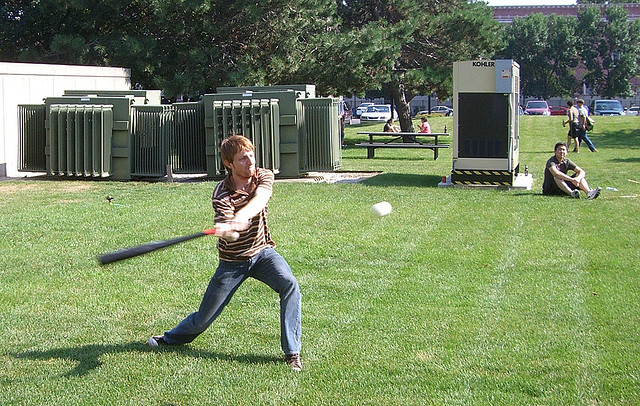

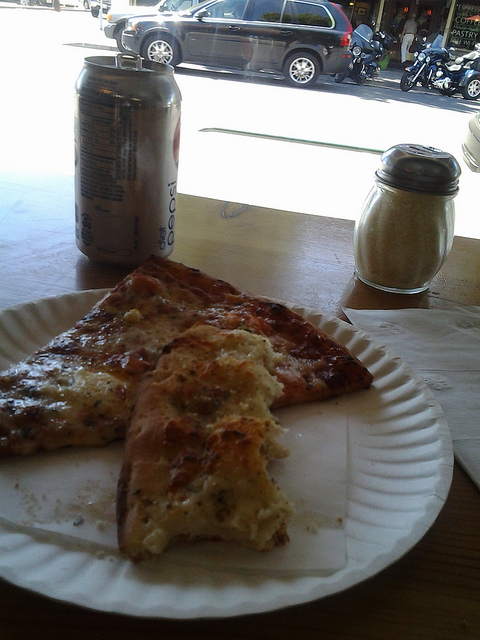

In [4]:
from google.colab.patches import cv2_imshow
import cv2
import os
import random

# Path to the directory containing the COCO dataset images
train_image_dir = "train2017"

# Get a list of image filenames in the directory
image_files = os.listdir(train_image_dir)

# Select a random sample of images to display
num_samples = 2
sample_images = random.sample(image_files, num_samples)

# Display each sample image
for image_file in sample_images:
    # Load the image using OpenCV
    image_path = os.path.join(train_image_dir, image_file)
    image = cv2.imread(image_path)

    # Display the image
    cv2_imshow(image)


In [5]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.15 🚀 Python-3.10.12 torch-2.2.1+cu121 CPU (Intel Xeon 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 68.6/107.7 GB disk)


In [7]:
from ultralytics import YOLO

# Load a model
model = YOLO('yolov8n.yaml')  # build a new model from YAML
model = YOLO('yolov8n.pt')  # load a pretrained model (recommended for training)
model = YOLO('yolov8n.yaml').load('yolov8n.pt')  # build from YAML and transfer weights

# Train the model


Transferred 355/355 items from pretrained weights


In [15]:
results = model.train(data='coco8.yaml', epochs=100, imgsz=640)

Ultralytics YOLOv8.2.15 🚀 Python-3.10.12 torch-2.2.1+cu121 CPU (Intel Xeon 2.20GHz)
engine/trainer: task=detect, mode=train, model=yolov8n.yaml, data=coco8.yaml, epochs=100, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train4, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, show_boxes=True, lin

100%|██████████| 433k/433k [00:00<00:00, 10.2MB/s]
Unzipping /content/datasets/coco8.zip to /content/datasets/coco8...: 100%|██████████| 25/25 [00:00<00:00, 1463.71file/s]

Dataset download success ✅ (1.0s), saved to /content/datasets



100%|██████████| 755k/755k [00:00<00:00, 16.1MB/s]


                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           


...

    100/100         0G     0.5718     0.5884      1.054         13        640: 100%|██████████| 1/1 [00:05<00:00,  5.21s/it]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:01<00:00,  1.91s/it]

                   all          4         17      0.949      0.391      0.421      0.302



100 epochs completed in 0.205 hours.
Optimizer stripped from runs/detect/train4/weights/last.pt, 6.6MB
Optimizer stripped from runs/detect/train4/weights/best.pt, 6.5MB

Validating runs/detect/train4/weights/best.pt...
Ultralytics YOLOv8.2.15 🚀 Python-3.10.12 torch-2.2.1+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8n summary (fused): 168 layers, 3151904 parameters, 0 gradients, 8.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:01<00:00,  1.27s/it]


                   all          4         17      0.541      0.859      0.873      0.621
                person          4         10      0.639        0.5       0.51      0.285
                   dog          4          1      0.316          1      0.995      0.597
                 horse          4          2      0.627          1      0.995      0.648
              elephant          4          2      0.385      0.656      0.745      0.303
              umbrella          4          1      0.536          1      0.995      0.995
          potted plant          4          1      0.741          1      0.995      0.895
Speed: 2.7ms preprocess, 297.4ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to runs/detect/train4


In [38]:
results = model.predict("/content/2441dfc8-2efe-4311-97bf-b788cf81712b.jpg")
result = results[0]
len(result.boxes)
box = result.boxes[0]
print("Object type:", box.cls)
print("Coordinates:", box.xyxy)
print("Probability:", box.conf)


image 1/1 /content/2441dfc8-2efe-4311-97bf-b788cf81712b.jpg: 640x480 4 persons, 2 umbrellas, 1 tie, 267.9ms
Speed: 7.1ms preprocess, 267.9ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)
Object type: tensor([0.])
Coordinates: tensor([[ 125.4620,  495.5531, 1059.2413, 1596.3300]])
Probability: tensor([0.8875])


In [39]:
cords = box.xyxy[0].tolist()
class_id = box.cls[0].item()
conf = box.conf[0].item()
print("Object type:", class_id)
print("Coordinates:", cords)
print("Probability:", conf)


Object type: 0.0
Coordinates: [125.46195983886719, 495.5531311035156, 1059.2413330078125, 1596.3299560546875]
Probability: 0.8875027894973755


In [40]:
print(result.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [41]:
cords = box.xyxy[0].tolist()
cords = [round(x) for x in cords]
class_id = result.names[box.cls[0].item()]
conf = round(box.conf[0].item(), 2)
print("Object type:", class_id)
print("Coordinates:", cords)
print("Probability:", conf)

Object type: person
Coordinates: [125, 496, 1059, 1596]
Probability: 0.89


In [42]:
for box in result.boxes:
  class_id = result.names[box.cls[0].item()]
  cords = box.xyxy[0].tolist()
  cords = [round(x) for x in cords]
  conf = round(box.conf[0].item(), 2)
  print("Object type:", class_id)
  print("Coordinates:", cords)
  print("Probability:", conf)
  print("---")

Object type: person
Coordinates: [125, 496, 1059, 1596]
Probability: 0.89
---
Object type: umbrella
Coordinates: [0, 545, 140, 706]
Probability: 0.61
---
Object type: person
Coordinates: [72, 664, 378, 1588]
Probability: 0.55
---
Object type: person
Coordinates: [790, 607, 1072, 1593]
Probability: 0.53
---
Object type: umbrella
Coordinates: [98, 167, 1200, 899]
Probability: 0.52
---
Object type: tie
Coordinates: [731, 1044, 896, 1600]
Probability: 0.36
---
Object type: person
Coordinates: [799, 609, 1073, 1035]
Probability: 0.25
---


In [43]:
def print_box(box):
    class_id, cords, conf = box
    print("Object type:", class_id)
    print("Coordinates:", cords)
    print("Probability:", conf)
    print("---")

[
    print_box([
        result.names[box.cls[0].item()],
        [round(x) for x in box.xyxy[0].tolist()],
        round(box.conf[0].item(), 2)
    ]) for box in result.boxes
]

Object type: person
Coordinates: [125, 496, 1059, 1596]
Probability: 0.89
---
Object type: umbrella
Coordinates: [0, 545, 140, 706]
Probability: 0.61
---
Object type: person
Coordinates: [72, 664, 378, 1588]
Probability: 0.55
---
Object type: person
Coordinates: [790, 607, 1072, 1593]
Probability: 0.53
---
Object type: umbrella
Coordinates: [98, 167, 1200, 899]
Probability: 0.52
---
Object type: tie
Coordinates: [731, 1044, 896, 1600]
Probability: 0.36
---
Object type: person
Coordinates: [799, 609, 1073, 1035]
Probability: 0.25
---


[None, None, None, None, None, None, None]

Object type: person
Coordinates: [125, 496, 1059, 1596]
Probability: 0.89
---
Object type: umbrella
Coordinates: [0, 545, 140, 706]
Probability: 0.61
---
Object type: person
Coordinates: [72, 664, 378, 1588]
Probability: 0.55
---
Object type: person
Coordinates: [790, 607, 1072, 1593]
Probability: 0.53
---
Object type: umbrella
Coordinates: [98, 167, 1200, 899]
Probability: 0.52
---
Object type: tie
Coordinates: [731, 1044, 896, 1600]
Probability: 0.36
---
Object type: person
Coordinates: [799, 609, 1073, 1035]
Probability: 0.25
---


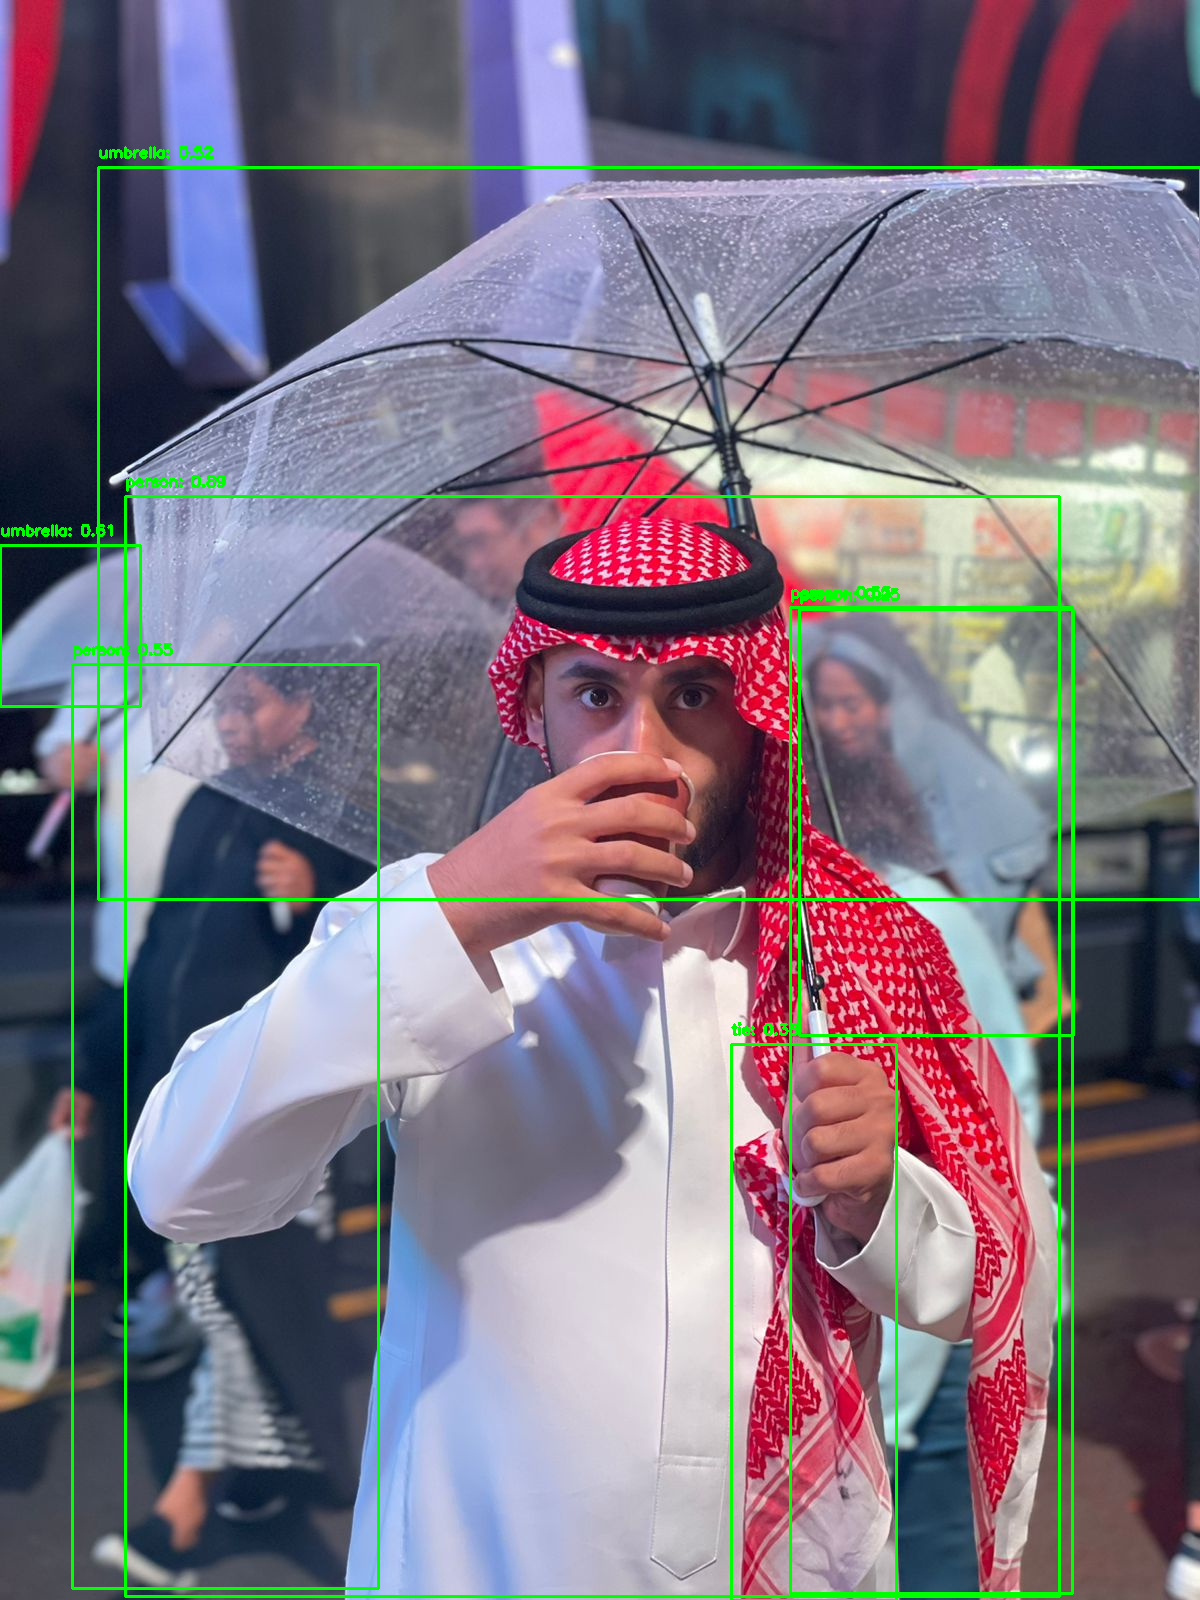

In [45]:
from google.colab.patches import cv2_imshow
import cv2

def print_box(box):
    class_id, cords, conf = box
    print("Object type:", class_id)
    print("Coordinates:", cords)
    print("Probability:", conf)
    print("---")

# Load the image
image = cv2.imread("/content/2441dfc8-2efe-4311-97bf-b788cf81712b.jpg")  # Replace "path_to_your_image.jpg" with the actual path to your image

# Iterate through the boxes and print the information
for box in result.boxes:
    class_id = result.names[box.cls[0].item()]
    coordinates = [round(x) for x in box.xyxy[0].tolist()]
    confidence = round(box.conf[0].item(), 2)
    print_box([class_id, coordinates, confidence])

    # Draw bounding box on the image
    pt1 = (coordinates[0], coordinates[1])
    pt2 = (coordinates[2], coordinates[3])
    cv2.rectangle(image, pt1, pt2, (0, 255, 0), 2)  # Green color for the bounding box

    # Add label to the image
    label = f"{class_id}: {confidence}"
    cv2.putText(image, label, (coordinates[0], coordinates[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

# Display the image with bounding boxes and labels
cv2_imshow(image)
